## ENEM: Rede Neural

-> A rede é o `MLPRegressor` da statstech: uma rede com camadas ReLU treinada por gradiente descendente em mini-lotes por um número fixo de épocas.

#### 0. Configuração inicial

In [7]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
from statstech.linear_model import Ridge
from statstech.model_selection import (
    GridSearchCV,
    KFold,
    cross_val_score,
    train_test_split,
)
from statstech.neural_network import MLPRegressor
from statstech.pipeline import Pipeline
from statstech.preprocessing import StandardScaler

from analysis.config import SEED, STYLE, TABLES
from analysis.evaluation import evaluate_regressor
from analysis.io import load_dataset
from analysis.report import save_figure, save_table

plt.style.use(STYLE)


def make_pipeline(model):
    # Padroniza X dentro de cada ajuste; o y é padronizado pela própria rede (scale_y).
    return Pipeline([("scaler", StandardScaler()), ("model", model)])


def rmse(y_true, y_pred):
    return evaluate_regressor(y_true, y_pred)["rmse"]

#### 1. Dados

In [8]:
data = load_dataset("enem")
X_train, y_train = data["X_train"], data["y_train"]
feature_names = data["feature_names"].tolist()

print(f"treino: {X_train.shape[0]} participantes, {X_train.shape[1]} colunas")
print(f"nota média: {y_train.mean():.1f} pontos, desvio padrão {y_train.std():.1f}")

treino: 38347 participantes, 41 colunas
nota média: 545.2 pontos, desvio padrão 87.7


#### 2. Validação

Temos duas formas de separar o treino: Cross Validation ou divisão fixa do terino em 80% e 20% por exemplo. 
O cv (cross validation) escolhe e compara já a divisão fixa auxiliaria em diagnósticos rápidos. 

In [9]:
cv = KFold(5, shuffle=True, random_state=SEED)
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2,
                                              random_state=SEED)
print(f"diagnóstico: {len(y_fit)} para ajustar, {len(y_val)} para validar")

diagnóstico: 30677 para ajustar, 7670 para validar


#### 3. Baselines: Média e Ridge

Para podermos comparar os resultados da rede neural com outros modelos, por exemplo, a média e o Ridge (melhor modelo linear)

In [10]:
mean_scores = []
for fit_idx, val_idx in cv.split(X_train):
    prediction = np.full(len(val_idx), y_train[fit_idx].mean())
    mean_scores.append(rmse(y_train[val_idx], prediction))
mean_scores = np.array(mean_scores)

ridge_search = GridSearchCV(make_pipeline(Ridge()),
                            {"model__alpha": list(np.logspace(-2, 4, 13))},
                            cv=cv, scoring="rmse").fit(X_train, y_train)
ridge_best = ridge_search.cv_results_[ridge_search.best_index_]
#TODO conferir com o resultado da regularização usando o Ridge

print(f"média do treino   RMSE {mean_scores.mean():.2f} ± {mean_scores.std(ddof=1):.2f}")
print(f"Ridge (alpha={ridge_search.best_params_['model__alpha']:.3g})  "
      f"RMSE {ridge_best['mean_score']:.2f} ± {ridge_best['std_score']:.2f}")

média do treino   RMSE 87.74 ± 0.61
Ridge (alpha=316)  RMSE 72.87 ± 0.83


#### 4. Teste inicial 

Antes da busca, podemos inicialmente fazer um simples teste para observar se a rede aprende e medir quanto tempo a busca vai levar. 

In [11]:
first = make_pipeline(MLPRegressor(hidden_layer_sizes=(64, 32), learning_rate=1e-3,
                                   max_iter=200, batch_size=64, random_state=SEED,
                                   scale_y=True))
start = time.perf_counter()
first.fit(X_fit, y_fit)
seconds_per_epoch = (time.perf_counter() - start) / 200

ridge_holdout = make_pipeline(Ridge(alpha=ridge_search.best_params_["model__alpha"]))
ridge_holdout.fit(X_fit, y_fit)

print(f"tempo: {seconds_per_epoch:.2f} s por época com {len(y_fit)} linhas")
print(f"RMSE da rede:  treino {rmse(y_fit, first.predict(X_fit)):.2f}   "
      f"validação {rmse(y_val, first.predict(X_val)):.2f}")
print(f"RMSE da Ridge: treino {rmse(y_fit, ridge_holdout.predict(X_fit)):.2f}   "
      f"validação {rmse(y_val, ridge_holdout.predict(X_val)):.2f}")

tempo: 0.08 s por época com 30677 linhas
RMSE da rede:  treino 71.57   validação 72.60
RMSE da Ridge: treino 72.86   validação 72.61


Obs.: Uma época leva 0,08 s com 30.677 linhas. É razoável dizer que a rede da statstech é rápida o bastante para esta base, sem precisar de subamostra.

Podemos observar também que a rede aprende! Na validação, ela empata com a Ridge (72,60 contra 72,61 pontos de RMSE) e no treino, a rede erra menos que a Ridge pois tende a ser mais flexível.

#### 5. Número de Épocas

Analisar o resultado do RMSE no treino e na validação.

In [12]:
epoch_grid = [25, 50, 100, 200]
curves = {}
holdout = {}
print("learning_rate  épocas  RMSE treino  RMSE validação")
for lr in [1e-3, 1e-2]:
    for epochs in epoch_grid:
        model = make_pipeline(MLPRegressor(hidden_layer_sizes=(64, 32), learning_rate=lr,
                                           max_iter=epochs, batch_size=64,
                                           random_state=SEED, scale_y=True))
        model.fit(X_fit, y_fit)
        holdout[lr, epochs] = (rmse(y_fit, model.predict(X_fit)),
                               rmse(y_val, model.predict(X_val)))
        print(f"{lr:13g}  {epochs:6d}  {holdout[lr, epochs][0]:11.2f}  "
              f"{holdout[lr, epochs][1]:14.2f}")
    curves[lr] = model.named_steps_["model"].loss_curve_  # a de 200 épocas

learning_rate  épocas  RMSE treino  RMSE validação
        0.001      25        73.06           73.14
        0.001      50        72.54           72.85
        0.001     100        72.11           72.69
        0.001     200        71.57           72.60
         0.01      25        71.65           72.74
         0.01      50        70.93           72.92
         0.01     100        69.89           73.28
         0.01     200        69.03           74.09


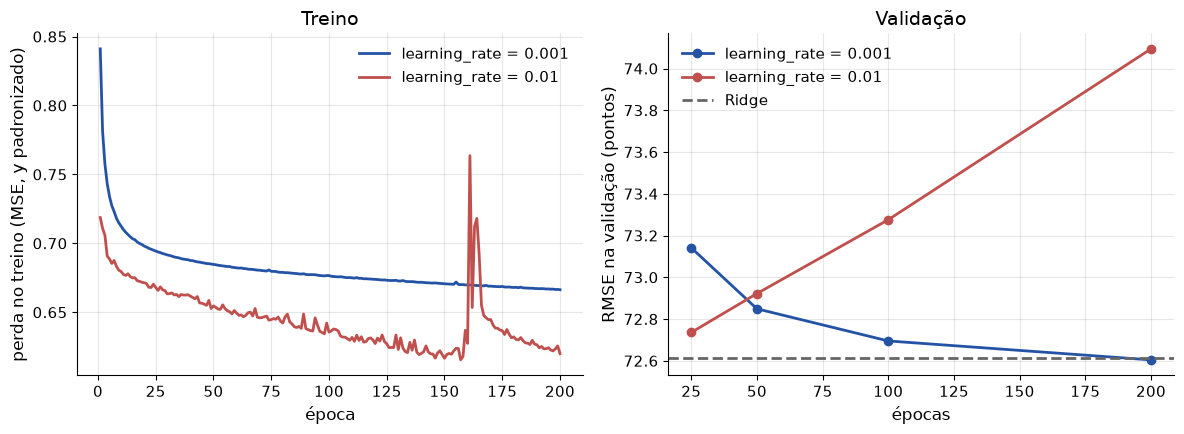

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for lr, curve in curves.items():
    axes[0].plot(np.arange(1, len(curve) + 1), curve, label=f"learning_rate = {lr:g}")
    axes[1].plot(epoch_grid, [holdout[lr, e][1] for e in epoch_grid], marker="o",
                 label=f"learning_rate = {lr:g}")
axes[1].axhline(rmse(y_val, ridge_holdout.predict(X_val)), color="0.4", ls="--",
                label="Ridge")
axes[0].set_xlabel("época")
axes[0].set_ylabel("perda no treino (MSE, y padronizado)")
axes[0].set_title("Treino")
axes[1].set_xlabel("épocas")
axes[1].set_ylabel("RMSE na validação (pontos)")
axes[1].set_title("Validação")
for ax in axes:
    ax.legend()
fig.tight_layout()
save_figure(fig, "enem_rede_perda")
plt.show()

Com passo 0,001, treino e validação caem juntos até 200 épocas, sem sobreajuste. Com passo 0,01, o RMSE de treino continua caindo, mas o de validação sobe depois de 25 épocas: a rede começa a decorar o treino.

Por isso o número de épocas (`max_iter`) entra na busca como hiperparâmetro.

#### 6. Busca de Hiperparâmetros



In [14]:
grid = {
    "model__hidden_layer_sizes": [(32,), (64, 32), (128, 64)],
    "model__learning_rate": [1e-3, 1e-2],
    "model__max_iter": [50, 200],
}
start = time.perf_counter()
search = GridSearchCV(
    make_pipeline(MLPRegressor(batch_size=64, random_state=SEED, scale_y=True)),
    grid, cv=cv, scoring="rmse",
).fit(X_train, y_train)
print(f"busca: {(time.perf_counter() - start) / 60:.1f} minutos\n")

rows = []
for r in search.cv_results_:
    p = r["params"]
    rows.append({"hidden_layer_sizes": str(p["model__hidden_layer_sizes"]),
                 "learning_rate": p["model__learning_rate"],
                 "max_iter": p["model__max_iter"],
                 "rmse": round(r["mean_score"], 3), "rmse_std": round(r["std_score"], 3)})
rows.sort(key=lambda row: row["rmse"])
save_table(rows, "enem_rede_busca")

print("camadas     learning_rate  épocas  RMSE")
for row in rows:
    print(f"{row['hidden_layer_sizes']:11s} {row['learning_rate']:13g}  {row['max_iter']:6d}  "
          f"{row['rmse']:.2f} ± {row['rmse_std']:.2f}")

busca: 10.1 minutos

camadas     learning_rate  épocas  RMSE
(32,)               0.001     200  72.64 ± 0.81
(32,)                0.01     200  72.81 ± 0.84
(32,)                0.01      50  72.83 ± 0.77
(64, 32)            0.001     200  72.84 ± 0.81
(128, 64)           0.001      50  73.03 ± 0.85
(64, 32)             0.01      50  73.05 ± 0.84
(64, 32)            0.001      50  73.11 ± 0.81
(128, 64)           0.001     200  73.12 ± 0.87
(32,)               0.001      50  73.21 ± 0.71
(128, 64)            0.01      50  73.45 ± 0.90
(64, 32)             0.01     200  74.94 ± 0.85
(128, 64)            0.01     200  78.44 ± 1.09


Podemos observar que a melhor configuração é a rede mais simples da grade: uma camada de 32 neurônios, passo 0,001 e 200 épocas. Como a diferença entre as outras é muito pequena, a escolha da mais simples é mais seguro pois a diferença entre as mais complexas pode ser apenas o aprendizado do ruído e o sobreajuste. 

#### 7. Treino x Validação

In [15]:
best_params = search.best_params_
best_model = make_pipeline(MLPRegressor(batch_size=64, random_state=SEED, scale_y=True))
best_model.set_params(**best_params).fit(X_fit, y_fit)
train_rmse = rmse(y_fit, best_model.predict(X_fit))
val_rmse = rmse(y_val, best_model.predict(X_val))
print("melhor:", best_params)
print(f"RMSE treino {train_rmse:.2f}   validação {val_rmse:.2f}   "
      f"diferença {val_rmse - train_rmse:.2f} pontos")

melhor: {'model__hidden_layer_sizes': (32,), 'model__learning_rate': 0.001, 'model__max_iter': 200}
RMSE treino 72.27   validação 72.31   diferença 0.04 pontos


#### 8. Variação entre sementes

Como o resultado depende da semente, vamos analisar 3 sementes diferentes com validação cruzada do melhor modelo.

In [16]:
seed_rmse = {}
for seed in [SEED, SEED + 1, SEED + 2]:
    model = make_pipeline(MLPRegressor(batch_size=64, random_state=seed, scale_y=True))
    model.set_params(**best_params)
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="rmse")
    seed_rmse[seed] = scores
    print(f"semente {seed}: RMSE {scores.mean():.2f} ± {scores.std(ddof=1):.2f}")

means = np.array([s.mean() for s in seed_rmse.values()])
print(f"\nmédia das 3 sementes: {means.mean():.2f}   "
      f"variação entre sementes: {means.max() - means.min():.2f} pontos")

semente 72: RMSE 72.64 ± 0.81
semente 73: RMSE 72.59 ± 0.94
semente 74: RMSE 72.63 ± 0.83

média das 3 sementes: 72.62   variação entre sementes: 0.05 pontos


#### 9. Rede Neural x Ridge

In [17]:
table = [
    {"model": "Média do treino", "rmse": mean_scores.mean(),
     "rmse_std": mean_scores.std(ddof=1)},
    {"model": "Ridge", "rmse": ridge_best["mean_score"], "rmse_std": ridge_best["std_score"]},
    {"model": "Rede neural (3 sementes)", "rmse": means.mean(),
     "rmse_std": np.mean([s.std(ddof=1) for s in seed_rmse.values()])},
]
for row in table:
    print(f"{row['model']:26s} RMSE {row['rmse']:.2f} ± {row['rmse_std']:.2f}")
gain = ridge_best["mean_score"] - means.mean()
print(f"\nganho da rede sobre a Ridge: {gain:.2f} pontos de RMSE")
save_table([{k: round(v, 3) if isinstance(v, float) else v for k, v in row.items()}
            for row in table], "enem_rede")

Média do treino            RMSE 87.74 ± 0.61
Ridge                      RMSE 72.87 ± 0.83
Rede neural (3 sementes)   RMSE 72.62 ± 0.86

ganho da rede sobre a Ridge: 0.24 pontos de RMSE


PosixPath('/home/al.dulce.costa/statstech-analise/results/tables/enem_rede.csv')

Podemos observar que a rede neural ganha do Ridge com uma pequena diferença de 0,25 ponto de RMSE. Um modelo capaz de capturar interações não lineares chega praticamente ao mesmo erro que um modelo que só soma efeitos, o que indica que a relação entre contexto familiar, escola e nota é quase aditiva nesta base.
Obs.: A comparação definitiva fica para a avaliação final no teste.

#### 10. Hiperparâmetros salvos para a avaliação final

In [18]:
fixed = {"model__batch_size": 64, "model__scale_y": True}
params = {k: list(v) if isinstance(v, tuple) else v for k, v in best_params.items()}
with open(TABLES / "enem_rede_hiperparametros.json", "w", encoding="utf-8") as f:
    json.dump({"seed": SEED, "fixed": fixed, "params": params,
               "rmse_cv": float(means.mean())}, f, indent=2)
print(params)

{'model__hidden_layer_sizes': [32], 'model__learning_rate': 0.001, 'model__max_iter': 200}


#### 11.  Comparação com Scikit-learn

Comparação do resultado com a biblioteca Statstech utilizando a mesma padronização de X e y e o mesmo cv, para a única diferença ser do treino (Adam e parada antecipada vs SGD com épocas fixas). 

In [19]:
pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 64.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 75.3 MB/s  0:00:00 82.4 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn]0m 5/6 [scikit-learn]]
Note: you may need to restart the kernel to use updated packages.


In [22]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import GridSearchCV as SklearnGridSearchCV
from sklearn.neural_network import MLPRegressor as SklearnMLP
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.preprocessing import StandardScaler as SklearnScaler

# Os mesmos 5 folds do cv da statstech.
folds = list(cv.split(X_train))

sk_model = SklearnPipeline([
    ("scaler", SklearnScaler()),
    ("mlp", TransformedTargetRegressor(          # padroniza o y, como o scale_y
        regressor=SklearnMLP(batch_size=64, max_iter=200, early_stopping=True,
                             random_state=SEED),
        transformer=SklearnScaler(),
    )),
])
sk_grid = {
    "mlp__regressor__hidden_layer_sizes": [(32,), (64, 32), (128, 64)],
    "mlp__regressor__alpha": [1e-4, 1e-3, 1e-2, 1e-1],        # regularização L2
    "mlp__regressor__learning_rate_init": [1e-3, 1e-2],
}
start = time.perf_counter()
sk_search = SklearnGridSearchCV(sk_model, sk_grid, cv=folds,
                                scoring="neg_root_mean_squared_error").fit(X_train, y_train)
print(f"busca do scikit-learn: {(time.perf_counter() - start) / 60:.1f} minutos")

best_i = sk_search.best_index_
sk_rmse = -sk_search.cv_results_["mean_test_score"][best_i]
sk_std = sk_search.cv_results_["std_test_score"][best_i]
print("melhor scikit-learn:", sk_search.best_params_)
print(f"scikit-learn: RMSE {sk_rmse:.2f} ± {sk_std:.2f}")
print(f"statstech:             RMSE {means.mean():.2f}")
print(f"Ridge:                 RMSE {ridge_best['mean_score']:.2f}")

busca do scikit-learn: 5.5 minutos
melhor scikit-learn: {'mlp__regressor__alpha': 0.1, 'mlp__regressor__hidden_layer_sizes': (128, 64), 'mlp__regressor__learning_rate_init': 0.001}
scikit-learn: RMSE 72.38 ± 0.75
statstech:             RMSE 72.62
Ridge:                 RMSE 72.87


O scikit-learn ajustado, com Adam, parada antecipada e regularização L2obteve um RMSE de 72,38, contra 72,62 da statstech e 72,87 da Ridge. Logo, podemos observar que a implementação da statstech não limitou o resultado. 

#### 12. Conclusão

- O resultado do MLPRegressor da statstech foi bem satisfatório: o desempenho dele foi próximo ao da rede do scikit-learn.

- A rede não se saiu melhor que o modelo linear por causa da própria base de dados: a relação entre contexto familiar, escola e nota é quase aditiva, e por isso não houve diferença clara entre um modelo linear e um não linear.

- Próximo passo: a avaliação final no teste.